In [1]:
# ============================================================
#  فایل پیش‌بینی: predict_fuel_real.py
#  وظیفه: بارگذاری مدل واقعی و پیش‌بینی مصرف برای مسافت جدید
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import joblib

In [2]:
# ---------- ۱. بارگذاری مدل ----------
MODEL_PATH = "model/fuel_real_model.pkl"
model = joblib.load(MODEL_PATH)

print("=" * 55)
print("مدل واقعی با موفقیت بارگذاری شد.")
print("=" * 55)
print(f"شیب (a): {model.coef_[0]:.4f}")
print(f"عرض از مبدأ (b): {model.intercept_:.4f}")
print("=" * 55)

مدل واقعی با موفقیت بارگذاری شد.
شیب (a): 0.0786
عرض از مبدأ (b): 1.1429


In [3]:
# ---------- ۲. پیش‌بینی برای ورودی‌های جدید ----------
مسافت‌های_جدید = [250, 450, 900]
پیش‌بینی‌ها = model.predict(np.array(مسافت‌های_جدید).reshape(-1, 1))

print("پیش‌بینی برای مسافت‌های جدید:")
print("-" * 55)
for m, p in zip(مسافت‌های_جدید, پیش‌بینی‌ها):
    print(f"مسافت {m:>4} کیلومتر → مصرف {p:>6.2f} لیتر")
print("=" * 55)

پیش‌بینی برای مسافت‌های جدید:
-------------------------------------------------------
مسافت  250 کیلومتر → مصرف  20.79 لیتر
مسافت  450 کیلومتر → مصرف  36.50 لیتر
مسافت  900 کیلومتر → مصرف  71.86 لیتر


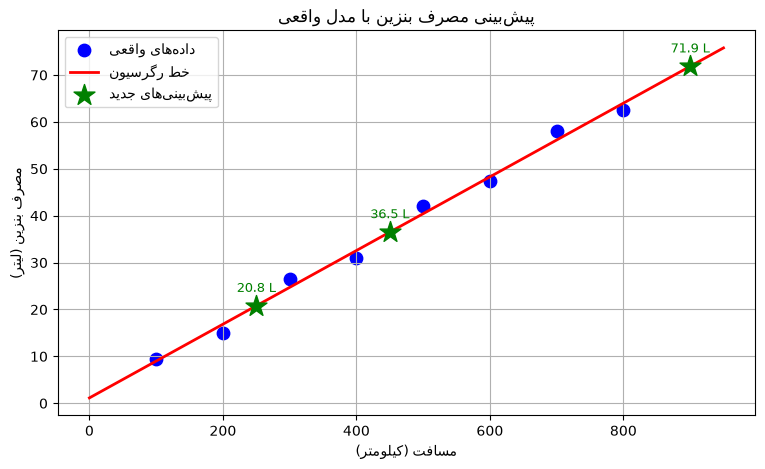

In [4]:
# ---------- ۳. رسم نمودار همراه با نقاط پیش‌بینی ----------
# داده‌های اصلی فقط برای رسم نمودار
X = np.array([[100], [200], [300], [400],
              [500], [600], [700], [800]])
y = np.array([9.5, 15.0, 26.5, 31.0,
              42.0, 47.5, 58.0, 62.5])

plt.figure(figsize=(9, 5))

plt.scatter(X, y, color='blue', s=80, label='داده‌های واقعی')

X_line = np.linspace(0, 950, 100).reshape(-1, 1)
y_line = model.predict(X_line)
plt.plot(X_line, y_line, color='red', linewidth=2, label='خط رگرسیون')

plt.scatter(مسافت‌های_جدید, پیش‌بینی‌ها, color='green',
            marker='*', s=250, zorder=5,
            label='پیش‌بینی‌های جدید')

for m, p in zip(مسافت‌های_جدید, پیش‌بینی‌ها):
    plt.annotate(f'{p:.1f} L', (m, p),
                 textcoords="offset points", xytext=(0, 10),
                 ha='center', fontsize=9, color='green')

plt.xlabel('مسافت (کیلومتر)')
plt.ylabel('مصرف بنزین (لیتر)')
plt.title('پیش‌بینی مصرف بنزین با مدل واقعی')
plt.legend()
plt.grid(True)
fig = plt.gcf()

In [5]:
PLOT_PATH = "results/fuel_real_prediction_plot.png"
fig.savefig(PLOT_PATH, dpi=150, bbox_inches='tight')
print(f"نمودار پیش‌بینی در فایل «{PLOT_PATH}» ذخیره شد.")

plt.show()

نمودار پیش‌بینی در فایل «results/fuel_real_prediction_plot.png» ذخیره شد.
